In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

def OS_fit(xdata,ydata):
    return curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], 
                           xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]) )

In [2]:
folder = '../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)

baseline = 'ssp534-over'
df = pd.read_csv(folder+'scen_%s.csv'%baseline)
df=df.set_index('year')
years = df.index.values
temps=df.to_numpy()

In [4]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,2227,2228,2229,2230,2231,2232,2233,2234,2235,2236
year,,,,,,,,,,,,,,,,,,,,,
1850,0.0125,-0.0153,0.0035,0.0768,0.0415,0.0397,0.0040,0.0204,0.0051,0.0292,...,0.0067,0.0096,-0.0040,0.0318,0.0014,-0.0136,0.0237,-0.0070,-0.0185,-0.0287
1851,0.0247,-0.0062,0.0118,0.0796,0.0496,0.0475,0.0123,0.0279,0.0141,0.0409,...,0.0163,0.0165,0.0045,0.0383,0.0123,-0.0004,0.0337,0.0029,-0.0049,-0.0118
1852,0.0343,0.0004,0.0164,0.0811,0.0555,0.0532,0.0172,0.0339,0.0204,0.0498,...,0.0235,0.0214,0.0109,0.0425,0.0208,0.0095,0.0411,0.0101,0.0056,0.0020
1853,0.0316,-0.0029,0.0062,0.0718,0.0490,0.0464,0.0085,0.0314,0.0130,0.0449,...,0.0201,0.0152,0.0083,0.0343,0.0180,0.0049,0.0361,0.0069,0.0041,0.0030
1854,0.0178,-0.0146,-0.0133,0.0531,0.0311,0.0289,-0.0097,0.0208,-0.0053,0.0274,...,0.0072,0.0004,-0.0026,0.0157,0.0055,-0.0121,0.0196,-0.0057,-0.0085,-0.0079


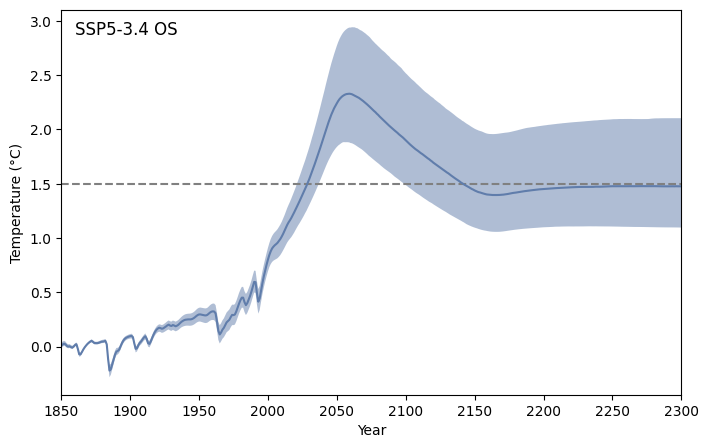

In [30]:
fig,ax=plt.subplots(figsize=(8,5))
ax.plot([1850,2300],[1.5]*2,c='gray',ls='--')
ax.fill_between(years,np.quantile(temps,0.1,axis=1),np.quantile(temps,0.9,axis=1),
                alpha=0.5,color='#607dab',edgecolor='none')
ax.plot(years,np.median(temps,axis=1),color='#607dab')

ax.set_xlabel('Year')
ax.set_ylabel('Temperature (°C)')
ax.set_xlim(1850,2300)
ax.text(1860,3,'SSP5-3.4 OS',ha='left',va='top',fontsize=12)
# ax.scatter([2015],[np.median(temps,axis=1)[2015-1850]])
fig.savefig('../../Figures/Overshoots/Conference/ssp534.png',bbox_inches='tight')

In [31]:
baseline = 'ssp534-over'
folder_ensemble = '../../Data/PROVIDE 2025/fair_temperatures/'
df_ensemble = pd.read_csv(folder_ensemble+'scen_%s.csv'%baseline)
df_ensemble=df_ensemble.set_index('year')
years_ensemble = df_ensemble.index.values
temps_ensemble=df_ensemble.to_numpy()

t_ref = 2015
xdata=years_ensemble[t_ref-1850:]-t_ref
popts = np.array([OS_fit(xdata,temps_ensemble[t_ref-1850:,r])[0] for r in range(temps_ensemble.shape[1])])
popt_of_m,_ = OS_fit(xdata,np.median(temps_ensemble[t_ref-1850:,:],axis=1))

In [36]:
popts.shape

(2237, 6)

<>:17: SyntaxWarning: invalid escape sequence '\D'
<>:21: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
<>:17: SyntaxWarning: invalid escape sequence '\D'
<>:21: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_298045/1162862911.py:17: SyntaxWarning: invalid escape sequence '\D'
  ax.text(popt_of_m[3]/2,popt_of_m[0],'$\Delta t_u$',va='bottom',ha='center',fontsize=12)
/tmp/ipykernel_298045/1162862911.py:21: SyntaxWarning: invalid escape sequence '\D'
  '$\Delta t_p$',va='top',ha='center',fontsize=12)
/tmp/ipykernel_298045/1162862911.py:25: SyntaxWarning: invalid escape sequence '\D'
  '$\Delta t_d$',va='top',ha='center',fontsize=12)


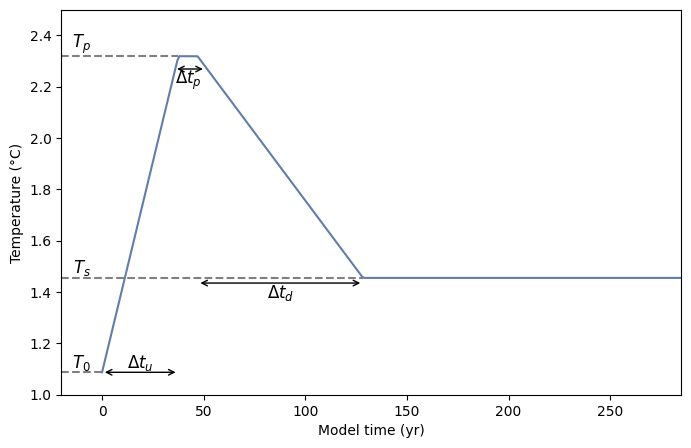

In [89]:
fig,ax=plt.subplots(figsize=(8,5))
dashed_ends = [0,popt_of_m[3],np.sum(popt_of_m[3:])]
temp_names = ['$T_0$', '$T_p$','$T_s$']
for i in range(3):
    ax.plot([-20,dashed_ends[i]],[popt_of_m[i]]*2,c='grey',ls='--')
    ax.text(-10,popt_of_m[i],temp_names[i],ha='center',va='bottom',fontsize=12)
ax.plot(xdata,OS_model(xdata,*popt_of_m),color='#607dab')#*np.median(popts,axis=0)))
ax.set_xlim(-20,285)
ax.set_ylim(1,2.5)
ax.set_xlabel("Model time (yr)")
ax.set_ylabel('Temperature (°C)')
# ax.scatter([0],[popt_of_m[0]],marker='x',c='k')
# ax.annotate(r'$T_0$',(0,popt_of_m[0]),(2,popt_of_m[0]),ha='left',va='center')

ax.annotate('',(0,popt_of_m[0]),(popt_of_m[3],popt_of_m[0]),
            arrowprops=dict(facecolor='black',arrowstyle='<->'))
ax.text(popt_of_m[3]/2,popt_of_m[0],'$\Delta t_u$',va='bottom',ha='center',fontsize=12)
ax.annotate('',(popt_of_m[3]-2,popt_of_m[1]-0.05),(popt_of_m[3]+popt_of_m[4]+4,popt_of_m[1]-0.05),
            arrowprops=dict(facecolor='black',arrowstyle='<->'))
ax.text(popt_of_m[3]+popt_of_m[4]/2,popt_of_m[1]-0.05,
            '$\Delta t_p$',va='top',ha='center',fontsize=12)
ax.annotate('',(popt_of_m[3]+popt_of_m[4],popt_of_m[2]-0.02),(np.sum(popt_of_m[3:]),popt_of_m[2]-0.02),
            arrowprops=dict(facecolor='black',arrowstyle='<->'))
ax.text(popt_of_m[3]+popt_of_m[4]+popt_of_m[5]/2,popt_of_m[2]-0.02,
            '$\Delta t_d$',va='top',ha='center',fontsize=12)
fig.savefig('../../Figures/Overshoots/Conference/stylised_OS.png',bbox_inches='tight')